# EYP3407 — Trabajo final, caso 07: Chicago Food Inspections

**Pregunta.** Entre establecimientos sometidos a una inspección rutinaria (`Canvass`),
¿cuáles tienen mayor probabilidad de obtener un resultado `Fail`?

| | |
|---|---|
| Población | Inspecciones `Canvass` 2019–2024 (sin reinspecciones ni denuncias) |
| Unidad | Una inspección rutinaria única (`inspection_id`) |
| Respuesta | `Fail` = 1; `Pass` / `Pass w/ Conditions` = 0; otros resultados se cuantifican y excluyen |
| Desarrollo | 2019–2022 |
| Reserva de prueba | 2023–2024: **no se examinan sus resultados** hasta la evaluación final |

Este notebook reúne todo el código del proyecto. Se ejecuta completo, en orden y desde
un kernel nuevo (*Kernel → Restart & Run All*), o desde la terminal con:

```bash
jupyter nbconvert --to notebook --execute --inplace proyecto_caso07.ipynb
```

**Contenido**

0. Configuración
1. Lectura y validación de datos
2. Definiciones del caso: población, respuesta, periodos e historia
3. Construcción de la muestra
4. Calidad de los datos
5. Establecimientos e historia disponible
6. Respuesta (sólo desarrollo)
7. Antecedentes previos y respuesta (sólo desarrollo)
8. Violaciones de la visita actual: por qué se excluyen
9. Cobertura geográfica
10. Síntesis y próximos pasos

> **Regla para proteger la reserva de prueba.** Todo lo que usa `results` o `violations`
> de las inspecciones objetivo se calcula sólo con 2019–2022. Del periodo 2023–2024 se
> informan únicamente tamaños, fechas y tipos de visita.

## 0. Configuración

**Antes de ejecutar:** el kernel debe ser el entorno del proyecto (`.venv`). En VS Code:
*Select Kernel* (arriba a la derecha) → *Python Environments* → **`.venv`**. Si aparece
`ModuleNotFoundError`, casi siempre es porque se eligió el Python del sistema
(`/usr/bin/python3`), que también dice "Python 3.9.6" pero no tiene las librerías.

In [1]:
# Comprobación del entorno: avisa si el kernel no es el .venv del proyecto.
import sys
from importlib.util import find_spec

print(f"Python en uso: {sys.executable}")
faltantes = [m for m in ("pandas", "numpy", "matplotlib") if find_spec(m) is None]
if faltantes:
    raise RuntimeError(
        f"Faltan librerías {faltantes} en este kernel ({sys.executable}). "
        "Seleccione el kernel '.venv' del proyecto (Select Kernel -> Python Environments -> .venv) "
        "o instale con: pip install -r requirements.txt"
    )
print("Entorno OK")

Python en uso: /Users/jmondaca/projects/Proyecto-Topicos/.venv/bin/python3
Entorno OK


In [2]:
import hashlib
import platform
import sys
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

INICIO = time.time()
SEMILLA = 20261012
np.random.seed(SEMILLA)

# Rutas relativas a la carpeta del notebook (raíz del repositorio).
RAIZ = Path.cwd()
DIR_DATOS = RAIZ / "datos"
ARCHIVO_DATOS = DIR_DATOS / "datos.csv"
ARCHIVO_DICCIONARIO = DIR_DATOS / "diccionario.csv"
DIR_SALIDA = RAIZ / "resultados" / "notebook"
DIR_TABLAS = DIR_SALIDA / "tablas"
DIR_FIGURAS = DIR_SALIDA / "figuras"
for d in (DIR_TABLAS, DIR_FIGURAS):
    d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"matplotlib {matplotlib.__version__} | {platform.platform()}")

Python 3.9.6 | pandas 2.3.3 | numpy 2.0.2 | matplotlib 3.9.4 | macOS-27.0.1-arm64-arm-64bit


In [3]:
# Estilo de figuras: marcas delgadas, ejes y grilla discretos.
AZUL, NARANJO = "#2a78d6", "#eb6834"
TEXTO, TEXTO_2, GRILLA = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRILLA, "axes.labelcolor": TEXTO_2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": TEXTO,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "font.size": 9, "legend.frameon": False, "lines.linewidth": 2,
})


def guardar_tabla(tabla, nombre, index=True):
    # Guarda la tabla en resultados/notebook/tablas y la devuelve para mostrarla.
    tabla.to_csv(DIR_TABLAS / f"{nombre}.csv", index=index, encoding="utf-8")
    return tabla


def mostrar_figura(fig, nombre):
    # Guarda la figura en resultados/notebook/figuras y la muestra en el notebook.
    fig.savefig(DIR_FIGURAS / f"{nombre}.png")
    plt.show()

## 1. Lectura y validación de datos

Decisiones de lectura (ver `datos/LEEME.txt`):

- UTF-8, coma separadora y punto decimal.
- **Sólo la celda vacía es un valor ausente.** No se usan los ausentes por defecto de pandas
  (`"NA"`, `"null"`, ...), para no convertir texto válido en faltante.
- Un ausente no equivale a cero: los identificadores se leen como enteros anulables (`Int64`)
  y `zip` como texto.
- Los textos (`results`, `violations`, nombres) se conservan sin recodificar.

Además se comprueba que el archivo sea la copia entregada (hash SHA-256), que las columnas
coincidan con `diccionario.csv` y que `inspection_id` sea una clave única.

In [4]:
# Hash de la copia entregada el 12-10-2026 (caso07_chicago_inspecciones.zip).
SHA256_ESPERADO = "6d250b8edf45f2f8cec3ee3a5ee91e648764ee3a32817faee4a35df16594d82a"


def sha256_archivo(ruta, bloque=1 << 20):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()


def leer_datos(ruta=ARCHIVO_DATOS, verificar_hash=True):
    if not ruta.exists():
        raise FileNotFoundError(
            f"No se encontró {ruta}. Descomprima caso07_chicago_inspecciones.zip en datos/.")
    if verificar_hash and sha256_archivo(ruta) != SHA256_ESPERADO:
        raise ValueError(f"{ruta.name} no coincide con la copia entregada.")

    df = pd.read_csv(ruta, dtype=str, keep_default_na=False, na_values=[""], encoding="utf-8")

    diccionario = pd.read_csv(ARCHIVO_DICCIONARIO, dtype=str, keep_default_na=False)
    if list(df.columns) != list(diccionario["variable"]):
        raise ValueError(f"Columnas distintas al diccionario: {list(df.columns)}")

    # errors="raise": si hubiera un valor no numérico o una fecha inválida, se detiene.
    for col in ["inspection_id", "license_"]:
        df[col] = pd.to_numeric(df[col], errors="raise").astype("Int64")
    for col in ["latitude", "longitude"]:
        df[col] = pd.to_numeric(df[col], errors="raise")
    df["inspection_date"] = pd.to_datetime(
        df["inspection_date"], format="%Y-%m-%dT%H:%M:%S.%f", errors="raise")

    if df["inspection_id"].isna().any() or df["inspection_id"].duplicated().any():
        raise ValueError("inspection_id no es una clave única y completa.")
    return df, diccionario


df, diccionario = leer_datos()
print(f"Filas: {len(df):,} | Columnas: {df.shape[1]} | inspection_id único: {df['inspection_id'].is_unique}")
print(f"Fechas: {df['inspection_date'].min():%Y-%m-%d} a {df['inspection_date'].max():%Y-%m-%d}")
display(diccionario)

Filas: 104,468 | Columnas: 17 | inspection_id único: True
Fechas: 2019-01-02 a 2024-12-31


,variable,nombre,tipo,descripcion
0,inspection_id,Inspection ID,number,
1,dba_name,DBA Name,text,Doing Business As
2,aka_name,AKA Name,text,Also Known As
3,license_,License #,number,
4,facility_type,Facility Type,text,
5,risk,Risk,text,
6,address,Address,text,
7,city,City,text,
8,state,State,text,
9,zip,Zip,number,


In [5]:
df.head()

,inspection_id,dba_name,aka_name,license_,facility_type,risk,address,city,state,zip,inspection_date,inspection_type,results,violations,latitude,longitude,location
0,2243957,TWO MILE COFFEE BAR,TWO MILE COFEE BAR,2641611,Restaurant,Risk 2 (Medium),1766 W 95TH ST,CHICAGO,IL,60643,2019-01-02,License,Not Ready,NaN,41.721260,-87.667257,"(41.72126016238349, -87.66725709711507)"
1,2243958,FAMILY DOLLART #32124,FAMILY DOLLAR,2630979,Grocery Store,Risk 3 (Low),1633 W MONTEREY AVE,CHICAGO,IL,60643,2019-01-02,License,Not Ready,NaN,41.689432,-87.663014,"(41.689431926833365, -87.66301447393185)"
2,2243959,CARMELO'S TACO PLACE,CARMELO'S TACO PLACE,2617376,Restaurant,Risk 1 (High),2746 W 59TH ST,CHICAGO,IL,60629,2019-01-02,License,Not Ready,NaN,41.786528,-87.693030,"(41.78652776994852, -87.69303014768134)"
3,2243960,AVONDALE TAP,AVONDALE TAP,2368771,Restaurant,Risk 1 (High),3634 W BELMONT AVE,CHICAGO,IL,60618,2019-01-02,Canvass,No Entry,NaN,41.939308,-87.718735,"(41.939307518988336, -87.71873540202452)"
4,2243961,MR. POLLO,MR. POLLO,2542966,Restaurant,Risk 1 (High),3026 W BELMONT AVE,CHICAGO,IL,60618,2019-01-02,Canvass,Pass w/ Conditions,"3. MANAGEMENT, FOOD EMPLOYEE AND CONDITIONAL E...",41.939467,-87.703811,"(41.93946745056518, -87.70381061827938)"


### 1.1 Perfil de columnas: tipo, faltantes y valores distintos

In [6]:
perfil = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "n_faltantes": df.isna().sum(),
    "pct_faltantes": (df.isna().mean() * 100).round(2),
    "n_unicos": df.nunique(dropna=True),
})
guardar_tabla(perfil, "01_perfil_columnas")

,tipo,n_faltantes,pct_faltantes,n_unicos
inspection_id,Int64,0,0.00,104468
dba_name,object,0,0.00,18186
aka_name,object,220,0.21,17369
license_,Int64,3,0.00,23599
facility_type,object,505,0.48,284
risk,object,18,0.02,4
address,object,0,0.00,22831
city,object,62,0.06,52
state,object,29,0.03,6
zip,object,5,0.00,100


## 2. Definiciones del caso

- **Población:** inspecciones con `inspection_type` exactamente igual a `"Canvass"`.
- **Respuesta:** `Fail` = 1; `Pass` o `Pass w/ Conditions` = 0. Los demás resultados
  (`Out of Business`, `No Entry`, `Not Ready`, `Business Not Located`) quedan como `NA`:
  **no se recodifican como 0**.
- **Periodos:** desarrollo 2019–2022; prueba 2023–2024.
- **Historia:** las otras visitas del paquete (de cualquier tipo) sirven como antecedentes,
  siempre que su fecha sea **estrictamente anterior** a la visita objetivo. Como la fuente no
  registra la hora, las visitas del mismo día no se usan como historia.
- **Enlace de historia:** por `license_`. La licencia 0 o ausente no permite enlazar.

In [7]:
TIPO_OBJETIVO = "Canvass"
RESULTADO_POSITIVO = "Fail"
RESULTADOS_NEGATIVOS = ("Pass", "Pass w/ Conditions")
ANIOS_DESARROLLO = (2019, 2022)
ANIOS_PRUEBA = (2023, 2024)


def normalizar_texto(serie):
    # Minúsculas y espacios colapsados; conserva NA.
    return serie.str.strip().str.lower().str.replace(r"\s+", " ", regex=True)


def periodo(fecha):
    anio = fecha.dt.year
    salida = pd.Series(pd.NA, index=fecha.index, dtype="string")
    salida[anio.between(*ANIOS_DESARROLLO)] = "desarrollo"
    salida[anio.between(*ANIOS_PRUEBA)] = "prueba"
    return salida


def respuesta_binaria(resultados):
    # 1 = Fail, 0 = Pass / Pass w/ Conditions, NA = otro resultado.
    y = pd.Series(pd.NA, index=resultados.index, dtype="Int8")
    y[resultados == RESULTADO_POSITIVO] = 1
    y[resultados.isin(RESULTADOS_NEGATIVOS)] = 0
    return y


def licencia_valida(licencia):
    return licencia.notna() & (licencia > 0)

### 2.1 Historia previa sin fuga de información

`agregar_historia` agrega a cada inspección objetivo:

| Variable | Definición |
|---|---|
| `tiene_historia` | Hubo alguna visita de la misma licencia en una fecha anterior |
| `fecha_previa`, `tipo_previo`, `resultado_previo` | Última visita anterior (cualquier tipo) |
| `dias_desde_previa` | Días entre esa visita y la inspección objetivo |
| `n_visitas_previas`, `n_fail_previos` | Conteos acumulados de visitas y de Fail en fechas anteriores |

La última visita se obtiene con `merge_asof(..., allow_exact_matches=False)`, que sólo toma
filas con fecha estrictamente menor. Los conteos se calculan por licencia y día, como acumulado
menos lo del mismo día. **Esta función es el punto donde podría colarse fuga; el equipo debe
entenderla bien.**

In [8]:
def agregar_historia(objetivo, todas):
    obj = objetivo.copy()
    obj["licencia_valida"] = licencia_valida(obj["license_"])

    hist = todas.loc[licencia_valida(todas["license_"]),
                     ["license_", "inspection_id", "inspection_date",
                      "inspection_type", "results"]].copy()
    hist["license_"] = hist["license_"].astype("int64")

    # Última visita estrictamente anterior.
    previas = (hist.sort_values(["inspection_date", "inspection_id"])
               .rename(columns={"inspection_type": "tipo_previo",
                                "results": "resultado_previo"}))
    previas["fecha_previa"] = previas["inspection_date"]
    previas = previas.drop(columns="inspection_id")

    validas = obj.loc[obj["licencia_valida"]].copy()
    validas["license_"] = validas["license_"].astype("int64")
    validas = validas.sort_values(["inspection_date", "inspection_id"])
    validas = pd.merge_asof(validas, previas, on="inspection_date", by="license_",
                            allow_exact_matches=False, direction="backward")

    # Conteos acumulados de visitas y Fail en fechas anteriores.
    por_dia = (hist.assign(es_fail=(hist["results"] == RESULTADO_POSITIVO).astype(int))
               .groupby(["license_", "inspection_date"])
               .agg(n_dia=("inspection_id", "size"), fail_dia=("es_fail", "sum"))
               .sort_index())
    acumulado = por_dia.groupby(level=0).cumsum()
    previo = pd.DataFrame({
        "n_visitas_previas": acumulado["n_dia"] - por_dia["n_dia"],
        "n_fail_previos": acumulado["fail_dia"] - por_dia["fail_dia"],
    }).reset_index()
    validas = validas.merge(previo, on=["license_", "inspection_date"], how="left")

    validas["tiene_historia"] = validas["fecha_previa"].notna()
    validas["dias_desde_previa"] = (validas["inspection_date"] - validas["fecha_previa"]).dt.days

    nuevas = ["tiene_historia", "fecha_previa", "tipo_previo", "resultado_previo",
              "dias_desde_previa", "n_visitas_previas", "n_fail_previos"]
    obj = obj.join(validas.set_index("inspection_id")[nuevas], on="inspection_id")
    obj["tiene_historia"] = obj["tiene_historia"].astype("boolean")
    obj.loc[~obj["licencia_valida"], "tiene_historia"] = pd.NA
    return obj


def construir_poblacion(df):
    canvass = df.loc[df["inspection_type"] == TIPO_OBJETIVO].copy()
    canvass["periodo"] = periodo(canvass["inspection_date"])
    canvass["y_fail"] = respuesta_binaria(canvass["results"])
    canvass = agregar_historia(canvass, df)
    return canvass.sort_values(["inspection_date", "inspection_id"]).reset_index(drop=True)


pob = construir_poblacion(df)
dev = pob.loc[pob["periodo"] == "desarrollo"].copy()                 # desarrollo, todos los resultados
dev_y = dev.loc[dev["y_fail"].notna()].copy()                         # desarrollo con respuesta
print(f"Canvass: {len(pob):,} | desarrollo: {len(dev):,} | prueba: {(pob['periodo'] == 'prueba').sum():,}")

Canvass: 52,675 | desarrollo: 33,999 | prueba: 18,676


In [9]:
# Comprobación rápida de la regla "estrictamente anterior": ninguna visita previa
# puede tener fecha igual o posterior a la inspección objetivo.
assert (pob["fecha_previa"].dropna() < pob.loc[pob["fecha_previa"].notna(), "inspection_date"]).all()
pob[["inspection_id", "license_", "inspection_date", "periodo", "tiene_historia",
     "fecha_previa", "tipo_previo", "dias_desde_previa", "n_visitas_previas"]].sample(5, random_state=SEMILLA)

,inspection_id,license_,inspection_date,periodo,tiene_historia,fecha_previa,tipo_previo,dias_desde_previa,n_visitas_previas
43096,2588423,3931156,2024-01-23,prueba,True,2023-12-11,Canvass,43.0,3
3694,2288521,1120038,2019-05-09,desarrollo,False,NaT,NaN,NaN,0
47254,2596492,2835750,2024-06-18,prueba,True,2022-03-11,License,830.0,1
1711,2268846,35960,2019-03-05,desarrollo,False,NaT,NaN,NaN,0
15721,2382836,1272982,2020-07-10,desarrollo,False,NaT,NaN,NaN,0


In [10]:
def tasa_fail(datos, por):
    # Tamaño, número de Fail y prevalencia por grupo (sólo filas con respuesta).
    t = (datos.loc[datos["y_fail"].notna()]
         .groupby(por, dropna=False, observed=True)["y_fail"]
         .agg(n="size", n_fail="sum"))
    t["n_fail"] = t["n_fail"].astype(int)
    t["tasa_fail"] = (t["n_fail"] / t["n"]).round(3)
    return t


def barras_tasa(t, titulo, nombre):
    fig, ax = plt.subplots(figsize=(7, 0.42 * len(t) + 1))
    ax.barh(t.index.astype(str), t["tasa_fail"], color=AZUL, height=0.6)
    for i, (p, n) in enumerate(zip(t["tasa_fail"], t["n"])):
        ax.text(p, i, f"  {p:.2f}  (n={n:,})", va="center", color=TEXTO_2, fontsize=8)
    ax.set_xlim(0, t["tasa_fail"].max() * 1.35)
    ax.set_xlabel("Proporción Fail")
    ax.grid(axis="y", visible=False)
    ax.set_title(titulo)
    mostrar_figura(fig, nombre)

## 3. Construcción de la muestra

Tipos de visita por periodo. Esta tabla incluye el periodo de prueba porque no usa resultados.

In [11]:
tipos = (df.assign(periodo=periodo(df["inspection_date"]))
         .pivot_table(index="inspection_type", columns="periodo",
                      values="inspection_id", aggfunc="size", fill_value=0))
tipos["total"] = tipos.sum(axis=1)
guardar_tabla(tipos.sort_values("total", ascending=False), "02_tipos_de_visita")

periodo,desarrollo,prueba,total
inspection_type,,,
Canvass,33999,18676,52675
License,9527,4876,14403
Canvass Re-Inspection,8077,4813,12890
Complaint,6413,3495,9908
Complaint Re-Inspection,2838,1521,4359
Non-Inspection,1835,2130,3965
License Re-Inspection,2480,1176,3656
Short Form Complaint,1471,686,2157
Recent Inspection,147,70,217


Tipo de visita por resultado, **sólo desarrollo 2019–2022**:

In [12]:
df_dev = df.loc[df["inspection_date"].dt.year.between(*ANIOS_DESARROLLO)]
cruce = pd.crosstab(df_dev["inspection_type"], df_dev["results"], margins=True, margins_name="total")
guardar_tabla(cruce.sort_values("total", ascending=False), "03_tipo_por_resultado_desarrollo")

results,Business Not Located,Fail,No Entry,Not Ready,Out of Business,Pass,Pass w/ Conditions,total
inspection_type,,,,,,,,
total,15,13136,3948,1504,5366,25452,17558,66979
Canvass,7,6764,1281,15,5292,10922,9718,33999
License,1,2313,243,1432,4,3643,1891,9527
Canvass Re-Inspection,0,906,81,3,20,4951,2116,8077
Complaint,5,2241,453,10,26,1811,1867,6413
Complaint Re-Inspection,0,416,38,0,6,1775,603,2838
License Re-Inspection,0,213,14,23,0,1451,779,2480
Non-Inspection,2,1,1801,9,14,7,1,1835
Short Form Complaint,0,216,24,5,1,794,431,1471


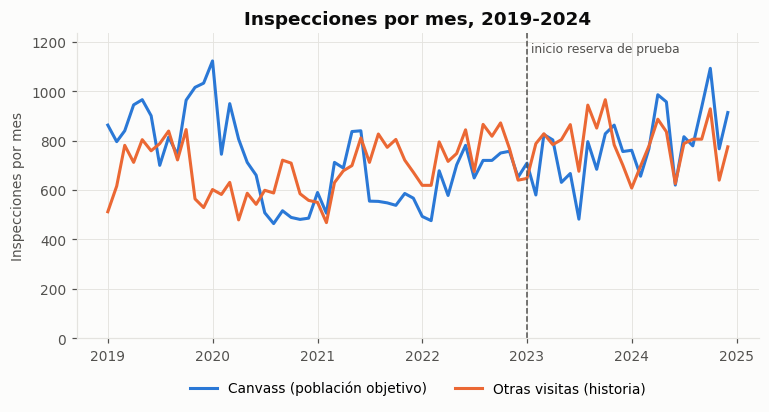

In [13]:
mes = df["inspection_date"].dt.to_period("M").dt.to_timestamp()
serie = (pd.crosstab(mes, df["inspection_type"] == TIPO_OBJETIVO)
         .rename(columns={True: "Canvass", False: "Otras visitas"}))
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(serie.index, serie["Canvass"], color=AZUL, label="Canvass (población objetivo)")
ax.plot(serie.index, serie["Otras visitas"], color=NARANJO, label="Otras visitas (historia)")
ax.set_ylim(0, serie.values.max() * 1.1)
ax.axvline(pd.Timestamp("2023-01-01"), color=TEXTO_2, lw=1, ls="--")
ax.text(pd.Timestamp("2023-01-15"), ax.get_ylim()[1] * 0.97, "inicio reserva de prueba",
        color=TEXTO_2, va="top", fontsize=8)
ax.set_title("Inspecciones por mes, 2019-2024")
ax.set_ylabel("Inspecciones por mes")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2)
mostrar_figura(fig, "fig01_inspecciones_por_mes")

### 3.1 Tabla de construcción de la muestra (exigida por la pauta §6.1)

In [14]:
prueba = pob.loc[pob["periodo"] == "prueba"]
con_lic = dev_y["licencia_valida"]
pasos = [
    ("Todas las visitas del paquete", len(df), df["license_"].nunique()),
    ("Inspecciones Canvass 2019-2024", len(pob), pob["license_"].nunique()),
    ("  Canvass desarrollo 2019-2022", len(dev), dev["license_"].nunique()),
    ("    con respuesta Fail / Pass / Pass w/ Conditions", len(dev_y), dev_y["license_"].nunique()),
    ("    con licencia válida para enlazar historia", int(con_lic.sum()),
     dev_y.loc[con_lic, "license_"].nunique()),
    ("  Canvass prueba 2023-2024 (resultados no examinados)", len(prueba), prueba["license_"].nunique()),
]
guardar_tabla(pd.DataFrame(pasos, columns=["paso", "filas", "licencias_distintas"]),
              "04_construccion_muestra", index=False)

,paso,filas,licencias_distintas
0,Todas las visitas del paquete,104468,23599
1,Inspecciones Canvass 2019-2024,52675,18081
2,Canvass desarrollo 2019-2022,33999,15060
3,con respuesta Fail / Pass / Pass w/ Condit...,27404,12303
4,con licencia válida para enlazar historia,27338,12302
5,Canvass prueba 2023-2024 (resultados no exam...,18676,11669


Resultados de Canvass en desarrollo que quedan fuera de la respuesta binaria (no se recodifican como 0):

In [15]:
guardar_tabla(dev.loc[dev["y_fail"].isna(), "results"].value_counts().rename("n").to_frame(),
              "05_resultados_excluidos_desarrollo")

,n
results,
Out of Business,5292
No Entry,1281
Not Ready,15
Business Not Located,7


## 4. Calidad de los datos

In [16]:
LAT_CHICAGO, LON_CHICAGO = (41.60, 42.05), (-87.95, -87.50)   # rectángulo aproximado de la ciudad

lic = df["license_"]
lat, lon = df["latitude"], df["longitude"]
fuera = lat.notna() & ~(lat.between(*LAT_CHICAGO) & lon.between(*LON_CHICAGO))
ft = normalizar_texto(df["facility_type"])
conteo_ft = ft.value_counts(dropna=False)

calidad = pd.Series({
    "license_ ausente": int(lic.isna().sum()),
    "license_ igual a 0": int((lic == 0).sum()),
    "city: variantes distintas": df["city"].nunique(),
    "city: filas que no son 'chicago' tras normalizar": int((normalizar_texto(df["city"]) != "chicago").sum()),
    "state distinto de IL o vacío": int((df["state"] != "IL").sum()),
    "facility_type: valores originales": df["facility_type"].nunique(),
    "facility_type: valores normalizados": ft.nunique(),
    "facility_type: categorías con < 30 visitas": int((conteo_ft < 30).sum()),
    "facility_type vacío": int(ft.isna().sum()),
    "coordenadas ausentes": int(lat.isna().sum()),
    "coordenadas fuera de Chicago": int(fuera.sum()),
}, name="n").to_frame()
guardar_tabla(calidad, "06_resumen_calidad")

,n
license_ ausente,3
license_ igual a 0,249
city: variantes distintas,52
city: filas que no son 'chicago' tras normalizar,185
state distinto de IL o vacío,44
facility_type: valores originales,284
facility_type: valores normalizados,258
facility_type: categorías con < 30 visitas,227
facility_type vacío,505
coordenadas ausentes,353


`risk` incluye categorías especiales (`All` y vacío):

In [17]:
guardar_tabla(df["risk"].value_counts(dropna=False).rename("n").to_frame(), "07_categorias_risk")

,n
risk,
Risk 1 (High),81491
Risk 2 (Medium),16705
Risk 3 (Low),6216
All,38
NaN,18


### 4.1 Posibles duplicados

La fuente advierte que pueden existir reportes duplicados. Se marcan las filas con la
misma licencia, fecha y tipo de visita. **Pendiente decidir su tratamiento antes de modelar.**

In [18]:
validas = df.loc[licencia_valida(lic)]
dup = validas.duplicated(["license_", "inspection_date", "inspection_type"], keep=False)
print(f"Filas posiblemente duplicadas: {int(dup.sum())}, "
      f"de ellas Canvass: {int((dup & (validas['inspection_type'] == TIPO_OBJETIVO)).sum())}")
guardar_tabla(validas.loc[dup].sort_values(["license_", "inspection_date"])
              [["inspection_id", "license_", "dba_name", "address", "inspection_date", "inspection_type"]],
              "08_posibles_duplicados", index=False).head(10)

Filas posiblemente duplicadas: 875, de ellas Canvass: 803


,inspection_id,license_,dba_name,address,inspection_date,inspection_type
82646,2584938,4207,CRESPO FOOD & LIQUOR,2157 W NORTH AVE,2023-11-09,Canvass
82648,2584940,4207,CRESPO FOOD & LIQUOR,2157 W NORTH AVE,2023-11-09,Canvass
9094,2294082,6277,THE NORTHSIDE STRETCH,3485 N CLARK ST,2019-06-24,Canvass
9113,2294101,6277,THE STRETCH BAR AND GRILL,3485 N CLARK ST,2019-06-24,Canvass
46136,2532173,7077,SHAY CHICAGO,222 W ONTARIO ST,2021-09-30,Canvass
46146,2532183,7077,ELECTRIC HOTEL,222 W ONTARIO ST,2021-09-30,Canvass
24514,2369517,9412,CORCORANS PANTRY INC,1105 W BRYN MAWR AVE,2020-04-21,Canvass
24518,2369521,9412,EDGEWATER FOOD WINE & SPIRITS,1105 W BRYN MAWR AVE,2020-04-21,Canvass
27178,2374205,10810,LAWRENCE & KENNEDY AMOCO,5027 W LAWRENCE AVE,2020-06-24,Canvass
27183,2374210,10810,LAWRENCE KENNEDY BP,5027 W LAWRENCE AVE,2020-06-24,Canvass


### 4.2 Numeración de violaciones

El PDF del diccionario describe violaciones 1–44 y 70 (esquema anterior al 1-7-2018).
Se verifica qué numeración aparece en los datos:

In [19]:
numeros = df["violations"].str.findall(r"(?:^|\| )(\d+)\. ").explode().dropna().astype(int)
print(f"Números de violación observados: {numeros.min()} a {numeros.max()} ({numeros.nunique()} distintos)")

Números de violación observados: 1 a 64 (64 distintos)


## 5. Establecimientos e historia disponible

`address` trae espacios finales inconsistentes. Sin normalizar, parece que muchas licencias
tienen varias direcciones. Además, una misma dirección puede tener varias licencias (locales
sucesivos o locales en el mismo edificio), así que **la historia se enlaza por licencia**.

In [20]:
dir_norm = normalizar_texto(validas["address"])
entidades = pd.Series({
    "licencias válidas distintas": validas["license_"].nunique(),
    "licencias con al menos un Canvass": pob.loc[pob["licencia_valida"], "license_"].nunique(),
    "licencias con > 1 dirección (sin normalizar)": int((validas.groupby("license_")["address"].nunique() > 1).sum()),
    "licencias con > 1 dirección (normalizada)": int((dir_norm.groupby(validas["license_"]).nunique() > 1).sum()),
    "licencias con > 1 nombre dba_name (normalizado)":
        int((normalizar_texto(validas["dba_name"]).groupby(validas["license_"]).nunique() > 1).sum()),
    "direcciones con > 1 licencia": int((validas.groupby(dir_norm)["license_"].nunique() > 1).sum()),
}, name="n").to_frame()
guardar_tabla(entidades, "09_entidades")

,n
licencias válidas distintas,23598
licencias con al menos un Canvass,18080
licencias con > 1 dirección (sin normalizar),9540
licencias con > 1 dirección (normalizada),107
licencias con > 1 nombre dba_name (normalizado),505
direcciones con > 1 licencia,4727


In [21]:
guardar_tabla(pd.DataFrame({
    "visitas_por_licencia": validas.groupby("license_").size().describe(),
    "canvass_por_licencia": pob.loc[pob["licencia_valida"]].groupby("license_").size().describe(),
}).round(2), "10_visitas_por_licencia")

,visitas_por_licencia,canvass_por_licencia
count,23598.00,18080.00
mean,4.42,2.91
std,3.37,1.83
min,1.00,1.00
25%,2.00,1.00
50%,3.00,2.00
75%,7.00,4.00
max,36.00,14.00


Canvass con alguna visita previa en el paquete, por año. **En 2019 la historia está truncada**
porque el paquete parte el 2-1-2019. Esta tabla no usa la respuesta, por eso incluye prueba.

In [22]:
anio_pob = pob["inspection_date"].dt.year.astype(str).rename("anio")
hist_anio = (pob.loc[pob["licencia_valida"]].groupby(anio_pob)["tiene_historia"]
             .agg(n="size", con_historia="sum"))
hist_anio["pct_con_historia"] = (hist_anio["con_historia"] / hist_anio["n"] * 100).round(1)
guardar_tabla(hist_anio, "11_historia_por_anio")

,n,con_historia,pct_con_historia
anio,,,
2019,10556,1245,11.8
2020,7930,6206,78.3
2021,7506,7198,95.9
2022,7931,7675,96.8
2023,8597,8369,97.3
2024,10028,9806,97.8


## 6. Respuesta (sólo desarrollo 2019–2022)

In [23]:
print(f"Inspecciones con respuesta: {len(dev_y):,} | Fail: {int(dev_y['y_fail'].sum()):,} | "
      f"prevalencia: {dev_y['y_fail'].mean():.3f}")
print("Composición de los resultados con respuesta:")
display(dev_y["results"].value_counts(normalize=True).round(3).to_frame("proporción"))
guardar_tabla(tasa_fail(dev_y, dev_y["inspection_date"].dt.year.astype(str).rename("anio")), "12_fail_por_anio")

Inspecciones con respuesta: 27,404 | Fail: 6,764 | prevalencia: 0.247
Composición de los resultados con respuesta:


,proporción
results,
Pass,0.399
Pass w/ Conditions,0.355
Fail,0.247


,n,n_fail,tasa_fail
anio,,,
2019,8353,1867,0.224
2020,6168,1551,0.251
2021,6239,1534,0.246
2022,6644,1812,0.273


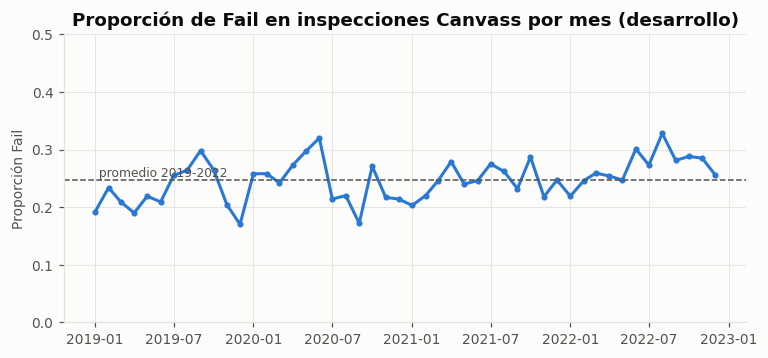

Inspecciones por mes: mínimo 345 (2020-11), máximo 979


In [24]:
mes_dev = dev_y["inspection_date"].dt.to_period("M").dt.to_timestamp().rename("mes")
por_mes = guardar_tabla(tasa_fail(dev_y, mes_dev), "13_fail_por_mes")
prom = dev_y["y_fail"].mean()

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(por_mes.index, por_mes["tasa_fail"], color=AZUL, marker="o", ms=3)
ax.axhline(prom, color=TEXTO_2, lw=1, ls="--")
ax.text(por_mes.index[0], prom, " promedio 2019-2022", color=TEXTO_2, va="bottom", fontsize=8)
ax.set_ylim(0, max(0.5, por_mes["tasa_fail"].max() * 1.1))
ax.set_title("Proporción de Fail en inspecciones Canvass por mes (desarrollo)")
ax.set_ylabel("Proporción Fail")
mostrar_figura(fig, "fig02_fail_por_mes_desarrollo")
print(f"Inspecciones por mes: mínimo {por_mes['n'].min()} ({por_mes['n'].idxmin():%Y-%m}), "
      f"máximo {por_mes['n'].max()}")

### 6.1 Por tipo de local (8 más frecuentes + otros)

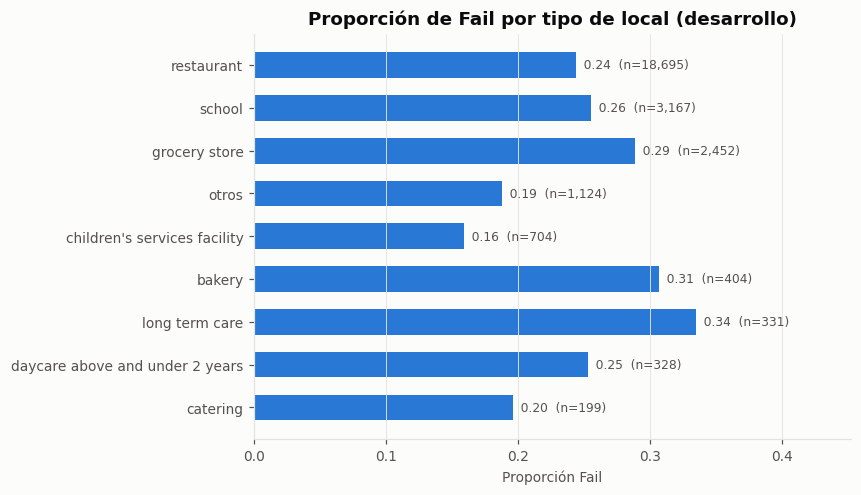

In [25]:
ft_dev = normalizar_texto(dev_y["facility_type"]).fillna("(vacío)")
top = ft_dev.value_counts().head(8).index
dev_y["tipo_local"] = ft_dev.where(ft_dev.isin(top), "otros")
por_tipo = guardar_tabla(tasa_fail(dev_y, "tipo_local").sort_values("n"), "14_fail_por_tipo_local")
barras_tasa(por_tipo, "Proporción de Fail por tipo de local (desarrollo)", "fig03_fail_por_tipo_local")

### 6.2 Por categoría de riesgo

Su uso como predictor requiere justificar que el nivel se conocía antes de la visita.
Según el diccionario, el riesgo determina la frecuencia de inspección.

In [26]:
guardar_tabla(tasa_fail(dev_y, "risk"), "15_fail_por_risk")

,n,n_fail,tasa_fail
risk,,,
Risk 1 (High),22650,5636,0.249
Risk 2 (Medium),3828,847,0.221
Risk 3 (Low),926,281,0.303


### 6.3 Por código postal

In [27]:
por_zip = guardar_tabla(tasa_fail(dev_y, "zip"), "16_fail_por_zip")
grandes = por_zip.loc[por_zip["n"] >= 50, "tasa_fail"]
print(f"Zips con respuesta: {len(por_zip)} | con menos de 50 inspecciones: {int((por_zip['n'] < 50).sum())}")
print(f"Proporción de Fail en zips con n >= 50: mín. {grandes.min():.3f}, máx. {grandes.max():.3f}")

Zips con respuesta: 77 | con menos de 50 inspecciones: 19
Proporción de Fail en zips con n >= 50: mín. 0.098, máx. 0.464


## 7. Antecedentes previos y respuesta (sólo desarrollo)

Asociaciones descriptivas: la frecuencia de visita depende del riesgo asignado y de las
denuncias, así que no son efectos causales.

In [28]:
dh = dev_y.loc[dev_y["licencia_valida"]].copy()
dh["historia"] = dh["tiene_historia"].map({True: "con visita previa", False: "sin visita previa"})
guardar_tabla(tasa_fail(dh, ["historia"]), "17_fail_por_tiene_historia")

,n,n_fail,tasa_fail
historia,,,
con visita previa,18506,4660,0.252
sin visita previa,8832,2083,0.236


Casi todas las inspecciones *sin visita previa* son de 2019, cuando la historia está truncada: la comparación anterior mezcla el efecto del año.

In [29]:
guardar_tabla(tasa_fail(dh, [dh["inspection_date"].dt.year.astype(str).rename("anio"), "historia"]),
              "17b_fail_por_anio_e_historia")

n  n_fail  tasa_fail
anio historia                                  
2019 con visita previa   817     173      0.212
     sin visita previa  7514    1689      0.225
2020 con visita previa  5119    1213      0.237
     sin visita previa  1041     333       0.32
2021 con visita previa  6087    1504      0.247
     sin visita previa   139      25       0.18
2022 con visita previa  6483    1770      0.273
     sin visita previa   138      36      0.261

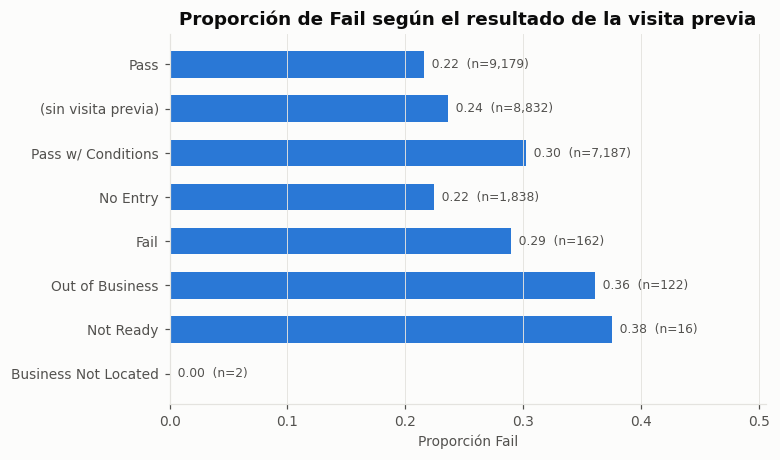

In [30]:
dh["resultado_previo_g"] = dh["resultado_previo"].fillna("(sin visita previa)")
por_prev = guardar_tabla(tasa_fail(dh, "resultado_previo_g").sort_values("n"), "18_fail_por_resultado_previo")
barras_tasa(por_prev, "Proporción de Fail según el resultado de la visita previa", "fig04_fail_por_resultado_previo")

Pocas visitas previas son `Fail` porque, tras un Fail, la visita siguiente suele ser una *Canvass Re-Inspection*.

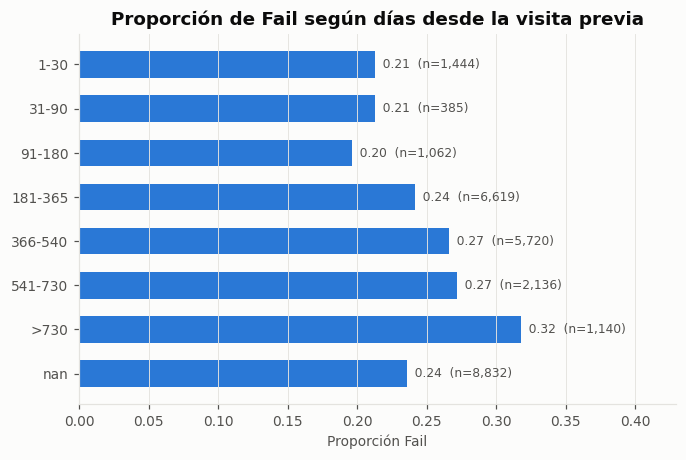

In [31]:
cortes = [0, 30, 90, 180, 365, 540, 730, np.inf]
etiquetas = ["1-30", "31-90", "91-180", "181-365", "366-540", "541-730", ">730"]
dh["dias_previa_g"] = pd.cut(dh["dias_desde_previa"], cortes, labels=etiquetas)
por_dias = guardar_tabla(tasa_fail(dh, "dias_previa_g"), "19_fail_por_dias_desde_previa")
barras_tasa(por_dias.iloc[::-1], "Proporción de Fail según días desde la visita previa",
            "fig05_fail_por_dias_desde_previa")

In [32]:
dh["n_fail_previos_g"] = dh["n_fail_previos"].clip(upper=3).astype(int).astype(str).replace("3", "3+")
guardar_tabla(tasa_fail(dh, "n_fail_previos_g"), "20_fail_por_n_fail_previos")

,n,n_fail,tasa_fail
n_fail_previos_g,,,
0,20738,4751,0.229
1,4915,1415,0.288
2,1243,410,0.33
3+,442,167,0.378


## 8. Violaciones de la visita actual: por qué se excluyen

`violations` describe los hallazgos de **la misma** inspección, así que revela la respuesta.
Se muestra sólo para documentar la exclusión. Las violaciones de visitas **anteriores** sí
pueden usarse como antecedentes.

,count,mean,std,min,25%,50%,75%,max
results,,,,,,,,
Fail,6764.0,7.95,4.76,0.0,4.0,7.0,11.0,33.0
Pass,10922.0,2.51,2.21,0.0,1.0,2.0,4.0,18.0
Pass w/ Conditions,9718.0,6.02,3.63,0.0,3.0,5.0,8.0,30.0


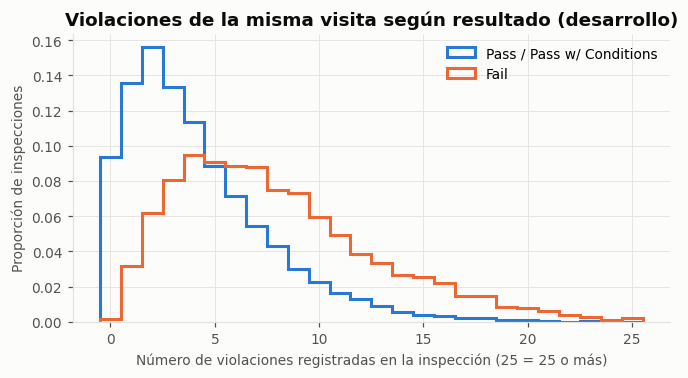

In [33]:
dev_y["n_violaciones"] = dev_y["violations"].fillna("").str.count(r"(?:^|\| )\d+\. ")
display(guardar_tabla(dev_y.groupby("results")["n_violaciones"].describe().round(2),
                      "21_violaciones_por_resultado_desarrollo"))

fig, ax = plt.subplots(figsize=(7, 3.4))
bins = np.arange(0, 27) - 0.5
for valor, color, etiqueta in [(0, AZUL, "Pass / Pass w/ Conditions"), (1, NARANJO, "Fail")]:
    x = dev_y.loc[dev_y["y_fail"] == valor, "n_violaciones"].clip(upper=25)
    ax.hist(x, bins=bins, density=True, histtype="step", color=color, lw=2, label=etiqueta)
ax.set_xlabel("Número de violaciones registradas en la inspección (25 = 25 o más)")
ax.set_ylabel("Proporción de inspecciones")
ax.set_title("Violaciones de la misma visita según resultado (desarrollo)")
ax.legend()
mostrar_figura(fig, "fig06_violaciones_por_resultado")

## 9. Cobertura geográfica (sin respuesta)

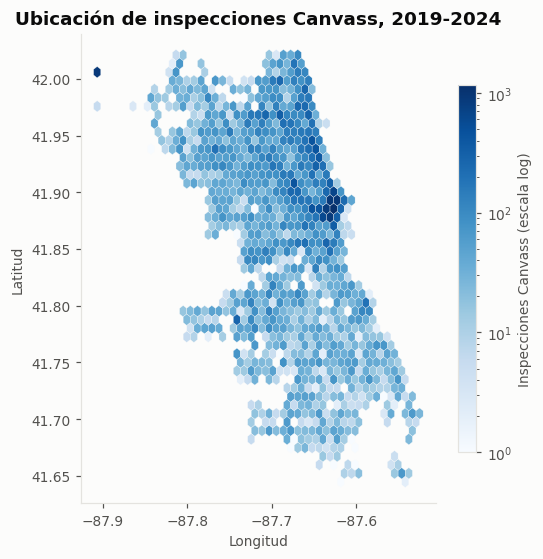

In [34]:
p = pob.loc[pob["latitude"].between(*LAT_CHICAGO) & pob["longitude"].between(*LON_CHICAGO)]
fig, ax = plt.subplots(figsize=(5.2, 6.2))
hb = ax.hexbin(p["longitude"], p["latitude"], gridsize=45, cmap="Blues", mincnt=1,
               bins="log", linewidths=0.2, edgecolors="#fcfcfb")
fig.colorbar(hb, ax=ax, shrink=0.7).set_label("Inspecciones Canvass (escala log)")
ax.set_aspect(1 / np.cos(np.deg2rad(41.85)))
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.grid(False)
ax.set_title("Ubicación de inspecciones Canvass, 2019-2024")
mostrar_figura(fig, "fig07_mapa_canvass")

## 10. Síntesis y próximos pasos

**Hallazgos del exploratorio** (las cifras exactas están en las celdas anteriores):

1. La historia de 2019 está truncada (≈12 % con visita previa, contra > 95 % desde 2021).
   *Decisión pendiente:* usar 2019 sólo como historia o entrenar con un indicador "sin historia".
2. La prevalencia de Fail en desarrollo es ≈ 0,25 y sube de 0,22 (2019) a 0,27 (2022): la
   referencia de probabilidad constante debe reestimarse en cada ventana de entrenamiento.
3. El número de Fail previos se asocia con más Fail (0,23 → 0,38): la historia es un buen candidato.
4. Hay ~800 Canvass posiblemente duplicados (misma licencia, fecha y tipo): hay que decidir cómo tratarlos.
5. `facility_type` tiene cientos de categorías raras: hay que agruparlas usando sólo entrenamiento.
6. `violations` de la visita actual queda excluida, porque revela la respuesta.

**Próximas secciones del notebook** (por agregar):

- Tabla de predictores admisibles y excluidos
- Particiones temporales de desarrollo
- Referencia, M1 logística, M2 árbol podado y M3 bosque aleatorio o boosting
- Umbral operativo, evaluación única en prueba, incertidumbre por licencia y dos sensibilidades

In [35]:
print(f"Notebook ejecutado completo en {time.time() - INICIO:.1f} s. "
      f"Tablas y figuras en {DIR_SALIDA.relative_to(RAIZ)}/")

Notebook ejecutado completo en 5.6 s. Tablas y figuras en resultados/notebook/
